# Exercise 1: Support Vector Machine Classification

**Subject:** Machine Learning Lab

**Topic:** Support Vector Machines (SVM)

## Aim
To implement a Support Vector Machine classifier using Python and evaluate its performance on the Iris dataset.

Dataset shape: (150, 2)
Classes: ['setosa' 'versicolor' 'virginica']

Training samples: 120
Testing samples: 30
Accuracy: 73.33 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.62      0.50      0.56        10
   virginica       0.58      0.70      0.64        10

    accuracy                           0.73        30
   macro avg       0.74      0.73      0.73        30
weighted avg       0.74      0.73      0.73        30



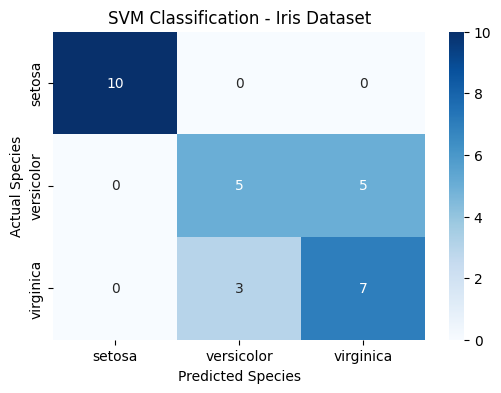

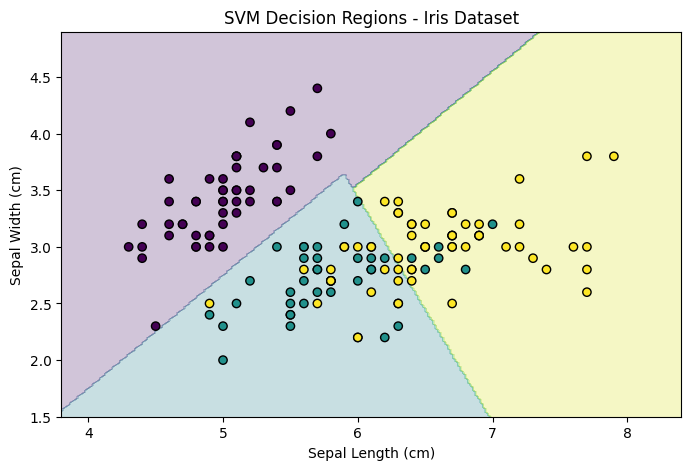


Example input: [5.1, 3.5]
Predicted species: setosa


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)

# Load the Iris dataset
iris = load_iris()
X = iris.data[:, :2]  # Sepal length and sepal width
y = iris.target

print("Dataset shape:", X.shape)
print("Classes:", iris.target_names)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the SVM model
model = SVC(kernel="linear", C=1.0)
model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = model.predict(X_test_scaled)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=iris.target_names, zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("SVM Classification - Iris Dataset")
plt.show()

# Visualize the decision regions
import numpy as np

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = scaler.transform(np.c_[xx.ravel(), yy.ravel()])
Z = model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
plt.scatter(
    X[:, 0], X[:, 1], c=y, edgecolors="black", cmap="viridis"
)
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("SVM Decision Regions - Iris Dataset")
plt.show()

# Example prediction
sample = [[5.1, 3.5]]
sample_scaled = scaler.transform(sample)
prediction = model.predict(sample_scaled)[0]

print("\nExample input:", sample[0])
print("Predicted species:", iris.target_names[prediction])

## Result

The Support Vector Machine (SVM) classifier was successfully implemented using the Iris dataset. The dataset was divided into training and testing sets, and the input features were standardized before training. The model achieved **73% test accuracy** on 30 test samples. A classification report and confusion matrix were generated to evaluate the model's performance.

## Conclusion

The experiment demonstrated the use of SVM for classifying Iris flower species. The model correctly classified the Setosa test samples, while some overlap between species affected the overall accuracy. This experiment illustrates how feature selection and the choice of kernel can influence classification performance.